# EDA: планировки ПИК для модели «картинка -> план»

Сервис «Своя планировка» должен по картинке планировки с сайта застройщика построить план квартиры в метрах:
помещения с типом, двери, окна, масштаб. Данные - планировки ПИК: картинки, нарисованные из векторных чертежей ПИК так
же, как на pik.ru, и разметка, построенная из тех же чертежей. В разделе 11 - сценарии для проверки агента, который
переставляет мебель по просьбе.

Слова: чертёж - одна картинка с разметкой (их 7 589, из них 491 с косыми стенами); планировка - группа чертежей с одинаковыми помещениями
(раздел 6); px - пиксель. Картинки и разметка в репозиторий не выкладываются: это материалы застройщика.

In [1]:
import hashlib
import json
import re
from itertools import combinations
from math import sqrt
from pathlib import Path

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.patches import Rectangle
from PIL import Image
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from shapely.geometry import Polygon
from sklearn.model_selection import StratifiedGroupKFold

DATASET = Path.home() / "svoya-ml" / "dataset-pik-v3"  # вне репозитория
AGENT = Path("..") / "data" / "agent_eval"  # сценарии агента, git-ignored

sns.set_theme(style="whitegrid", font_scale=0.9)
plt.rcParams["figure.dpi"] = 150
pd.set_option("display.width", 160)


def load_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def show(title, series):  # короткая таблица «название: значение»
    print(title)
    for name, value in series.items():
        print(f"  {name}: {value}")

## 1. Что лежит на диске

Две папки: `images` - картинки планировок, `labels` - разметка к ним, по одному файлу на планировку с одинаковым именем.
Картинки без разметки - чертежи, которые сборщик набора отбросил; в анализ они не входят.

In [2]:
for folder in ("images", "labels"):
    files = sorted((DATASET / folder).iterdir())
    size_mb = sum(f.stat().st_size for f in files) / 2**20
    print(f"{folder:7s} {len(files)} файлов {set(f.suffix for f in files)}, {size_mb:.0f} МБ")
image_names = {f.stem for f in (DATASET / "images").iterdir()}
label_names = {f.stem for f in (DATASET / "labels").iterdir()}
print(
    "у каждой разметки есть картинка:",
    label_names <= image_names,
    "; картинок без разметки:",
    len(image_names - label_names),
)

images  8169 файлов {'.png'}, 792 МБ
labels  7589 файлов {'.json'}, 32 МБ
у каждой разметки есть картинка: True ; картинок без разметки: 580


Одна запись - картинка PNG и JSON с разметкой в пикселях этой картинки, например `1dubr-1-4-1k-41-4`:

| Поле | Что это | Пример |
|---|---|---|
| `code` | код планировки: ЖК, корпус, число комнат, площадь | `1dubr-1-4-1k-41-4` |
| `w`, `h`, `margin` | размер картинки и поля вокруг чертежа, px | 1984, 1984, 192 |
| `m_per_px` | метров в одном пикселе | 0,00698 (0,7 см) |
| `total_m2` | общая площадь квартиры с сайта | 41,4 |
| `numbers_source` | откуда числа площадей на картинке: `site` - с сайта pik.ru, `floor` - посчитаны по чертежу | `floor` |
| `rooms[]` | помещения: `kind` - тип буквой, `name`, `polygon` - контур точками в px, `number` - число на картинке, `area_m2` - площадь контура | кухня-гостиная: 20,3 на картинке, контур 20,29 м² |
| `doors[]` | двери: `class` (`door`, `entrance`, `balcony`), `rect` - прямоугольник x0, y0, x1, y1, `segment` - отрезок вдоль стены, `hinge` - петля, `room_from`, `room_to`, `swing_into` - куда открывается | `door` из кухни в комнату, открывается в комнату |
| `windows[]` | окна: `room` - в каком помещении, `rect`, `segment` - отрезок вдоль стены | окно в кухне |
| `slanted` | есть ли в квартире косая стена | `false` |
| `walls[]` | стены прямоугольниками x0, y0, x1, y1 | 16 стен |

Остальные поля служебные и в анализе не используются.

In [3]:
LIVING = ["студия", "1", "2", "3+"]


def living_from_code(code):  # комнатность зашита в код: ...-st-... студия, ...-1k-... одна комната
    value = re.search(r"-(st|\dk)-", code).group(1)  # "st" или "1k", "2k", ...
    if value == "st":
        return "студия"
    return "3+" if int(value[0]) >= 3 else value[0]


labels = [load_json(p) for p in sorted((DATASET / "labels").glob("*.json"))]
FLAT_FIELDS = ["code", "w", "h", "margin", "m_per_px", "total_m2", "numbers_source", "slanted"]
flats = pd.DataFrame(
    [
        {k: d[k] for k in FLAT_FIELDS}
        | {
            "living_bin": living_from_code(d["code"]),
            "n_rooms": len(d["rooms"]),
            "n_doors": len(d["doors"]),
            "n_windows": len(d["windows"]),
            "area_rooms": sum(r["area_m2"] for r in d["rooms"]),
        }
        for d in labels
    ]
)
rooms = pd.DataFrame(
    [
        r | {"code": d["code"], "m_per_px": d["m_per_px"], "numbers_source": d["numbers_source"]}
        for d in labels
        for r in d["rooms"]
    ]
)
doors = pd.DataFrame([x | {"code": d["code"], "m_per_px": d["m_per_px"]} for d in labels for x in d["doors"]])
windows = pd.DataFrame([w | {"code": d["code"], "m_per_px": d["m_per_px"]} for d in labels for w in d["windows"]])
walls = pd.DataFrame([{"code": d["code"], "rect": w, "m_per_px": d["m_per_px"]} for d in labels for w in d["walls"]])
assert flats.code.is_unique
print(f"квартир {len(flats)}, помещений {len(rooms)}, дверей {len(doors)}, окон {len(windows)}, стен {len(walls)}")

квартир 7589, помещений 48420, дверей 33864, окон 25481, стен 230739


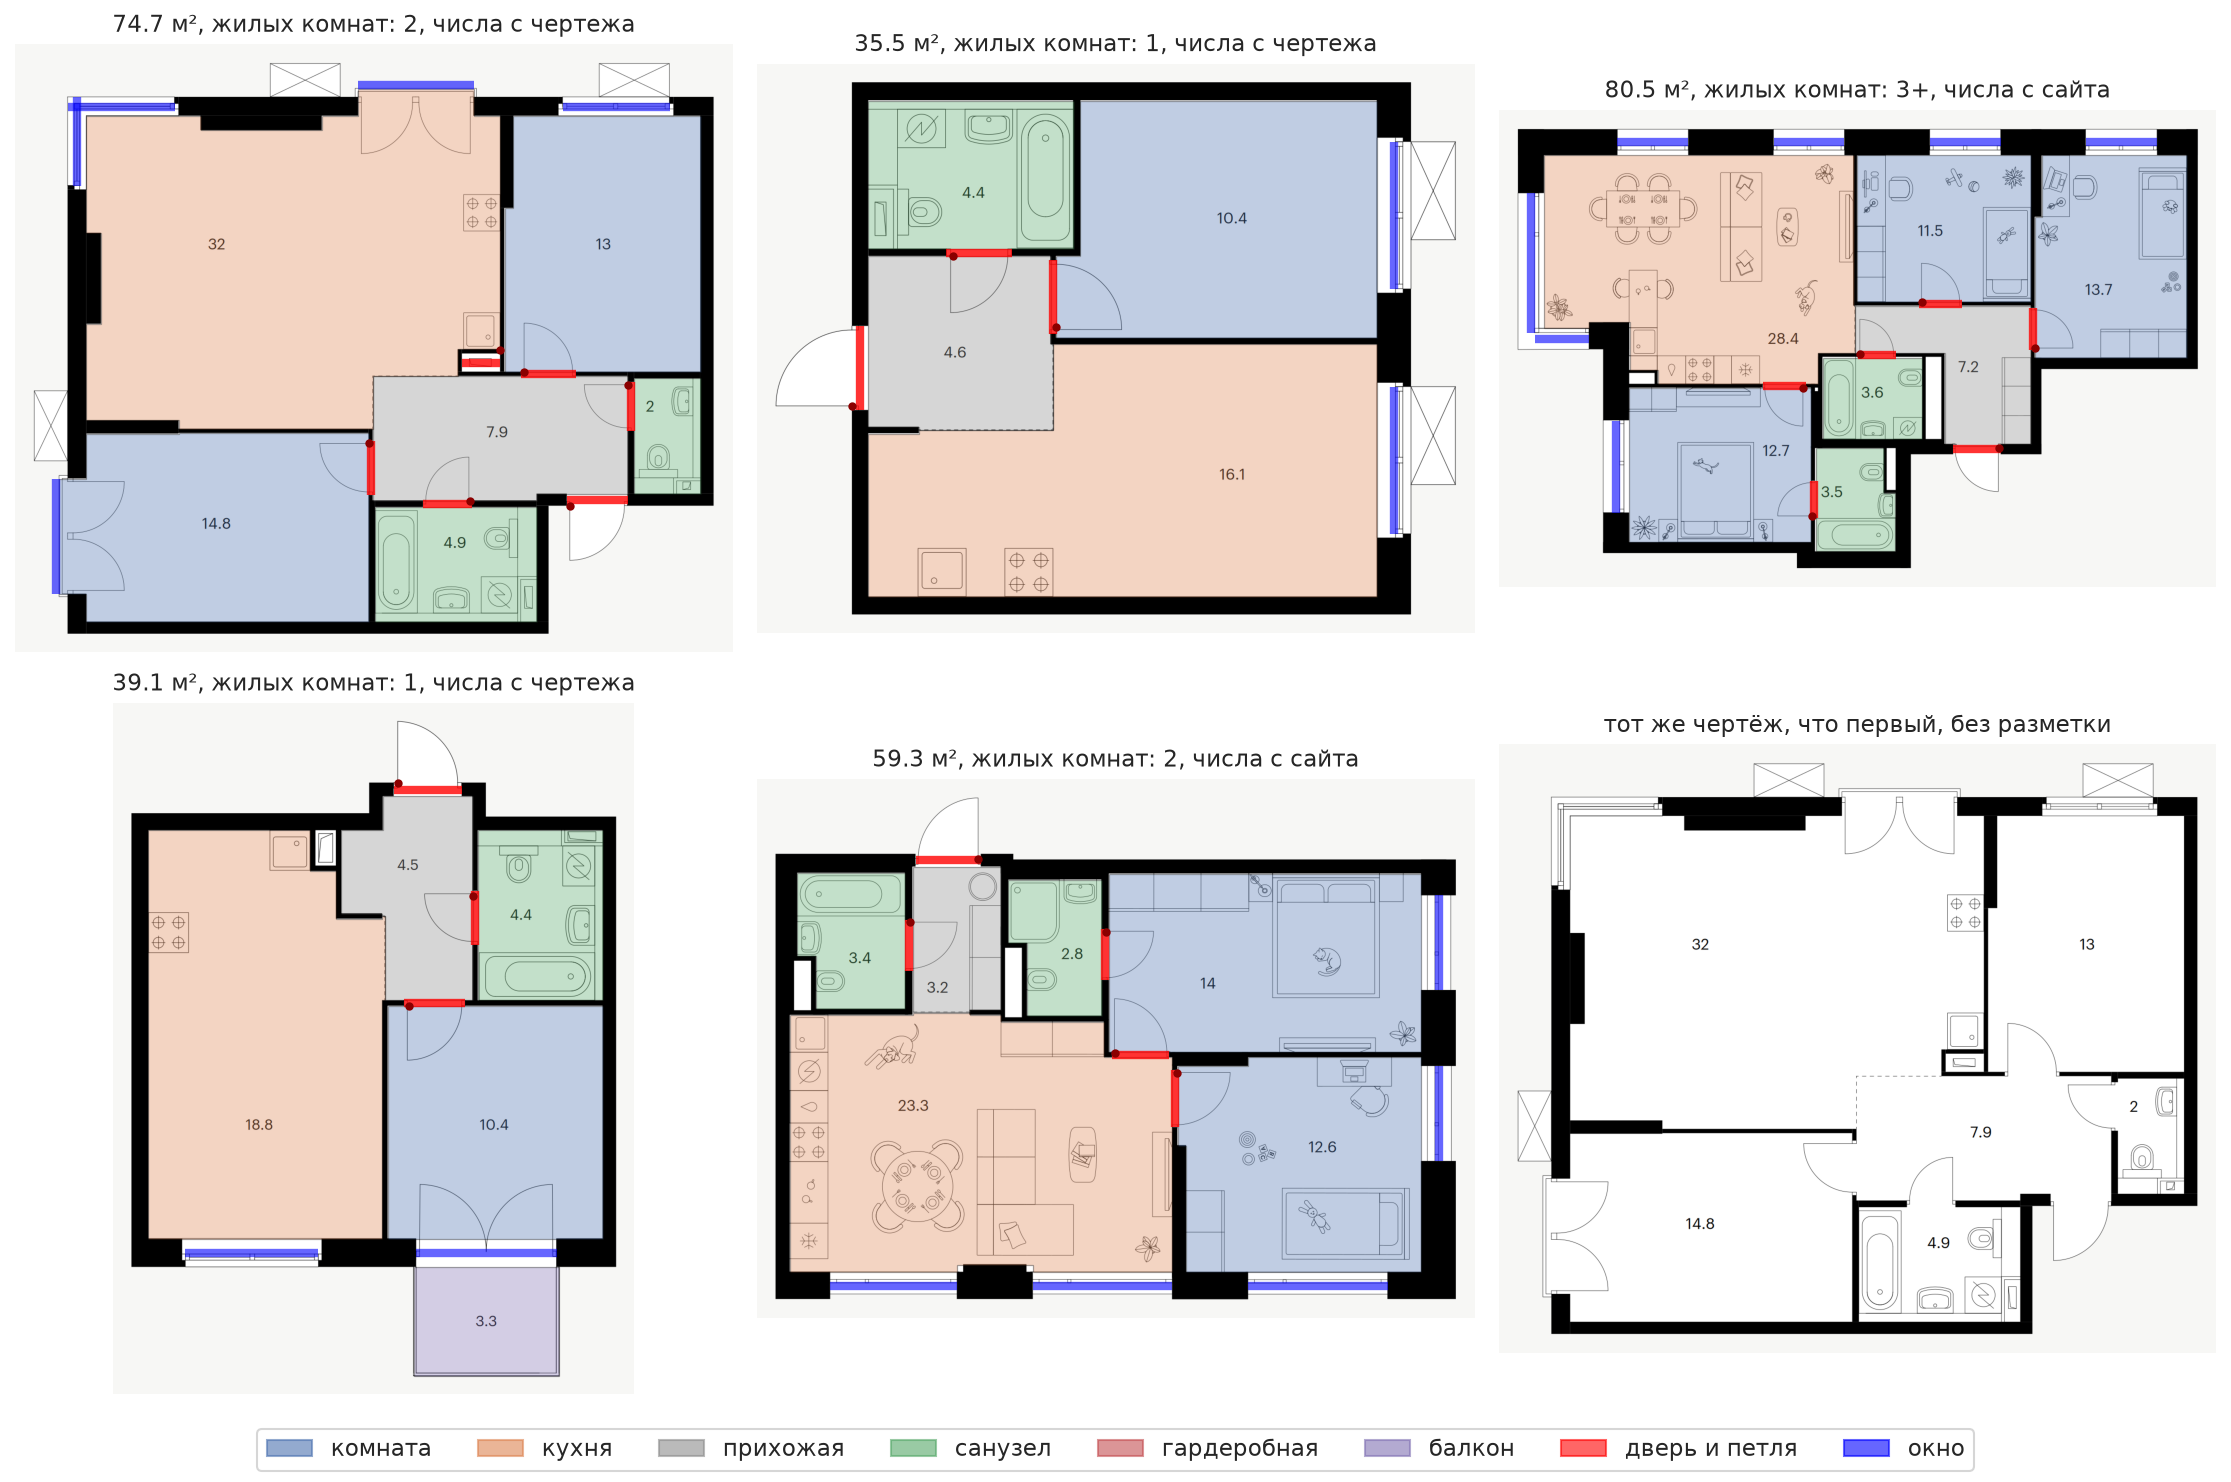

In [4]:
SOURCE_NAME = {"site": "с сайта", "floor": "с чертежа"}
KIND_NAME = {
    "r": "комната",
    "c": "кухня",
    "h": "прихожая",
    "s": "санузел",
    "g": "гардеробная",
    "b": "балкон",
    "f": "постирочная",
    "l": "терраса",
}
KIND_COLOR = {"r": "#4c72b0", "c": "#dd8452", "h": "#8c8c8c", "s": "#55a868", "g": "#c44e52", "b": "#8172b3"}


def show_drawing(ax, code, with_labels=True, title=""):
    image = mpimg.imread(DATASET / "images" / f"{code}.png")
    ax.imshow(image)
    ys, xs = np.where(image[..., :3].min(axis=2) < 0.85)  # обрезаем серые поля вокруг чертежа
    ax.set_xlim(xs.min() - 40, xs.max() + 40)
    ax.set_ylim(ys.max() + 40, ys.min() - 40)
    ax.set_axis_off()
    ax.set_title(title, fontsize=11)
    if not with_labels:
        return
    label = load_json(DATASET / "labels" / f"{code}.json")
    for r in label["rooms"]:
        ax.add_patch(
            MplPolygon(
                r["polygon"], facecolor=KIND_COLOR.get(r["kind"], "#ccb974"), alpha=0.35, edgecolor="black", lw=0.6
            )
        )
    for d in label["doors"]:
        ax.plot(*zip(*d["segment"], strict=True), color="red", lw=4, alpha=0.8, solid_capstyle="butt")
        ax.plot(*d["hinge"], "o", color="darkred", markersize=3)
    for w in label["windows"]:
        ax.plot(*zip(*w["segment"], strict=True), color="blue", lw=4, alpha=0.6, solid_capstyle="butt")


sample = flats.sample(6, random_state=7)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, (_, f) in zip(axes.flat[:5], sample.head(5).iterrows(), strict=True):
    show_drawing(
        ax, f.code, title=f"{f.total_m2} м², жилых комнат: {f.living_bin}, числа {SOURCE_NAME[f.numbers_source]}"
    )
show_drawing(axes.flat[5], sample.code.iloc[0], with_labels=False, title="тот же чертёж, что первый, без разметки")
handles = [Rectangle((0, 0), 1, 1, color=c, alpha=0.6) for c in list(KIND_COLOR.values()) + ["red", "blue"]]
fig.legend(
    handles, [KIND_NAME[k] for k in KIND_COLOR] + ["дверь и петля", "окно"], loc="lower center", ncol=8, fontsize=11
)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

На чертеже нарисована мебель, напечатаны площади помещений, двери показаны дугой; названий помещений нет. Разметка
обводит помещение по внутренним краям стен, поэтому у контура много изломов. Балкон размечен целиком.

## 2. Картинки

Размер картинок, масштаб и размер самых мелких объектов в пикселях.

In [5]:
png_size = pd.DataFrame(
    [Image.open(DATASET / "images" / f"{c}.png").size for c in flats.code], columns=["png_w", "png_h"]
)
flats = pd.concat([flats, png_size], axis=1)
show(
    "размер PNG, px (самые частые):", (flats.png_w.astype(str) + " x " + flats.png_h.astype(str)).value_counts().head(3)
)
print("PNG совпадает с w, h из разметки у всех:", ((flats.png_w == flats.w) & (flats.png_h == flats.h)).all())
print(
    f"длинная сторона 1984 px у {(flats[['png_w', 'png_h']].max(axis=1) == 1984).mean():.1%} картинок, "
    f"самая маленькая длинная сторона {flats[['png_w', 'png_h']].max(axis=1).min()} px; "
    f"поля вокруг чертежа 192 px у {(flats.margin == 192).mean():.0%}"
)
low, mid, high = (flats.m_per_px * 100).quantile([0.01, 0.5, 0.99])
print(f"масштаб, см на пиксель: 1% {low:.2f}, медиана {mid:.2f}, 99% {high:.2f}")


def short_side(rect):
    return min(rect[2] - rect[0], rect[3] - rect[1])


def long_side(rect):
    return max(rect[2] - rect[0], rect[3] - rect[1])


walls["thick_px"] = walls.rect.map(short_side)
rooms["min_side_px"] = rooms.polygon.map(lambda p: min(np.ptp(np.array(p), axis=0)))


def seg_len(segment):  # длина отрезка двери или окна вдоль стены
    (x0, y0), (x1, y1) = segment
    return float(np.hypot(x1 - x0, y1 - y0))


doors["width_px"] = doors.segment.map(seg_len)
sizes = (
    pd.DataFrame(
        {
            "толщина стены": walls.thick_px,
            "меньшая сторона помещения": rooms.min_side_px,
            "ширина двери": doors.width_px,
        }
    )
    .describe(percentiles=[0.01, 0.5, 0.99])
    .loc[["1%", "50%", "99%"]]
    .round(0)
)
print("\nразмеры в пикселях:")
print(sizes)

размер PNG, px (самые частые):
  1984 x 1984: 5567
  1984 x 1793: 13
  1984 x 1717: 11
PNG совпадает с w, h из разметки у всех: True
длинная сторона 1984 px у 90.8% картинок, самая маленькая длинная сторона 1774 px; поля вокруг чертежа 192 px у 91%
масштаб, см на пиксель: 1% 0.51, медиана 0.67, 99% 1.26



размеры в пикселях:
     толщина стены  меньшая сторона помещения  ширина двери
1%             1.0                       66.0          63.0
50%           15.0                      290.0         122.0
99%           76.0                      666.0         190.0


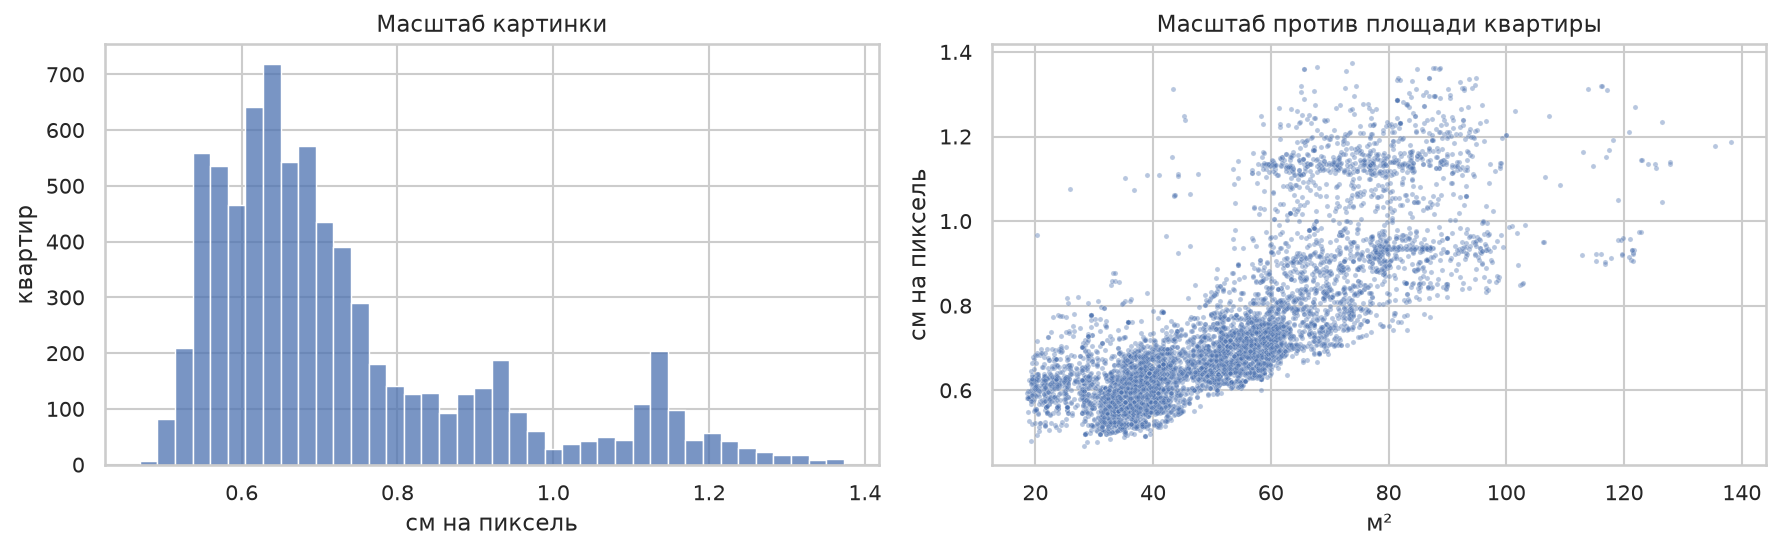

корреляция масштаба с площадью: 0.79


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(flats.m_per_px * 100, bins=40, ax=axes[0])
axes[0].set(title="Масштаб картинки", xlabel="см на пиксель", ylabel="квартир")
sns.scatterplot(data=flats, x="total_m2", y=flats.m_per_px * 100, s=6, alpha=0.4, ax=axes[1])
axes[1].set(title="Масштаб против площади квартиры", xlabel="м²", ylabel="см на пиксель")
plt.tight_layout()
plt.show()
print(f"корреляция масштаба с площадью: {np.corrcoef(flats.m_per_px, flats.total_m2)[0, 1]:.2f}")

Картинка 1984 x 1984 px у 73% чертежей; длинная сторона 1984 px у 91%, у остальных от 1774 px. Стена обычно 15 px, дверь и
самое узкое помещение - от 64 px. Если уменьшить картинку вдвое, стена станет 7 px. В одном пикселе от 0,5 до 1,3 см:
длинная сторона картинки почти одна и та же, поэтому маленькие квартиры нарисованы крупнее.

## 3. Квартиры

доля квартир по числу жилых комнат:
  студия: 0.09
  1: 0.35
  2: 0.37
  3+: 0.18
     площадь, м²  помещений  дверей  окон
min         18.6        2.0     1.0   0.0
5%          25.4        4.0     2.0   1.0
50%         50.3        6.0     5.0   3.0
95%         85.9       10.0     7.0   6.0
max        138.2       15.0    10.0  14.0
число площади с сайта у 23.4% квартир


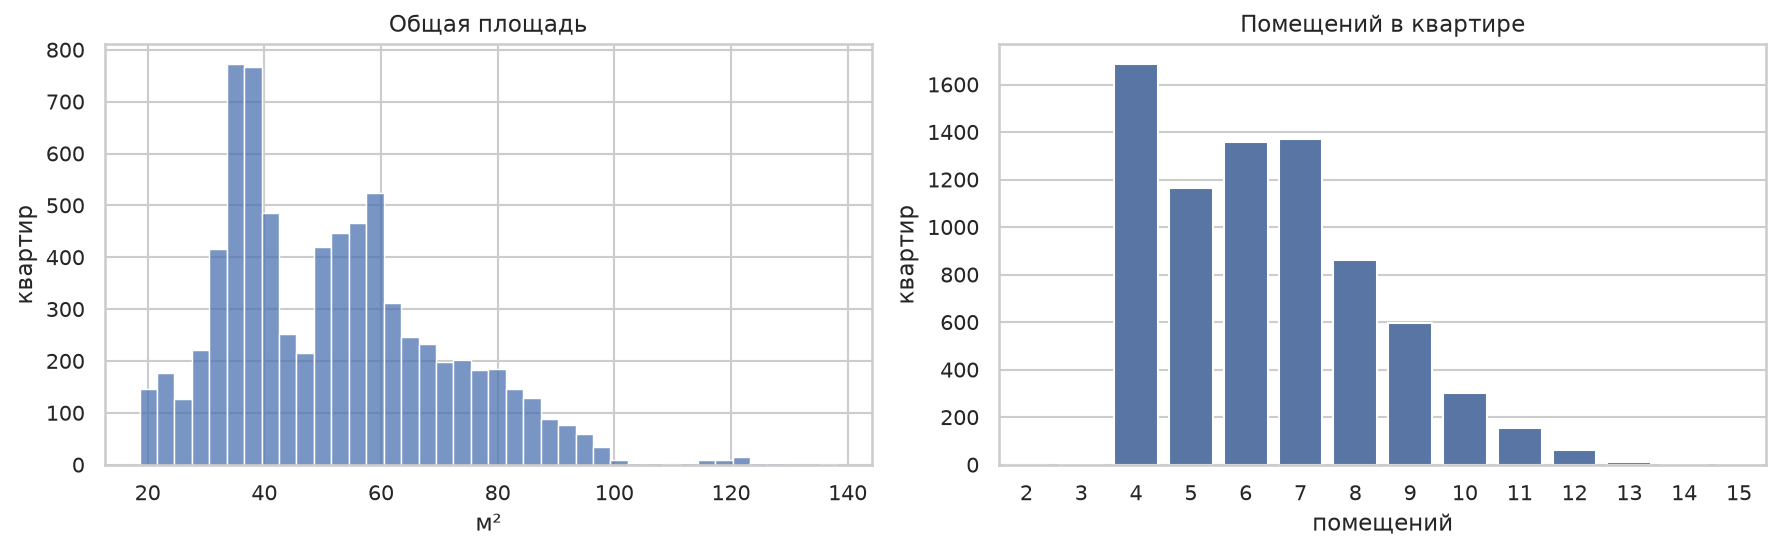

In [7]:
show("доля квартир по числу жилых комнат:", flats.living_bin.value_counts(normalize=True).reindex(LIVING).round(2))
COUNT_NAME = {"total_m2": "площадь, м²", "n_rooms": "помещений", "n_doors": "дверей", "n_windows": "окон"}
print(
    flats[list(COUNT_NAME)]
    .rename(columns=COUNT_NAME)
    .describe(percentiles=[0.05, 0.5, 0.95])
    .loc[["min", "5%", "50%", "95%", "max"]]
    .round(1)
)
print(f"число площади с сайта у {(flats.numbers_source == 'site').mean():.1%} квартир")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(flats.total_m2, bins=40, ax=axes[0])
axes[0].set(title="Общая площадь", xlabel="м²", ylabel="квартир")
sns.countplot(data=flats, x="n_rooms", ax=axes[1])
axes[1].set(title="Помещений в квартире", xlabel="помещений", ylabel="квартир")
plt.tight_layout()
plt.show()

Студий 9%, однокомнатных 35%, двухкомнатных 37%, с тремя и больше комнатами 18%. Площадь от 19 до 138 м², чаще всего
35-40 и 55-60 м². У 90% квартир 4-10 помещений, 2-7 дверей, 1-6 окон.

## 4. Помещения

In [8]:
kinds = rooms.kind.value_counts().rename("помещений").to_frame()
kinds["доля"] = (kinds["помещений"] / len(rooms)).round(3)
kinds["квартир"] = rooms.groupby("kind").code.nunique()
kinds["медиана м²"] = rooms.groupby("kind").area_m2.median().round(1)
kinds.index = [KIND_NAME.get(k, f"прочее ({k})") for k in kinds.index]
print(kinds)

             помещений   доля  квартир  медиана м²
комната          13494  0.279     7585        11.4
санузел          11661  0.241     7585         3.6
прихожая          9512  0.196     7566         4.3
кухня             7576  0.156     7570        17.2
гардеробная       3320  0.069     2656         3.2
балкон            2406  0.050     1897         2.1
постирочная        243  0.005      237         3.1
терраса             69  0.001       58         4.0
прочее (p)          68  0.001       68         3.4
прочее (u)          32  0.001       32         2.9
прочее (d)          31  0.001       30         9.6
прочее (o)           4  0.000        4         8.4
прочее (t)           4  0.000        4         5.9


квартир с косой стеной: 491 (6.5%); помещений с косой стеной: 1200 (2.5%)
прямоугольных помещений (4 вершины): 30.0%; стены только горизонтальные и вертикальные: 97.5%; 12 и больше вершин: 15.8%


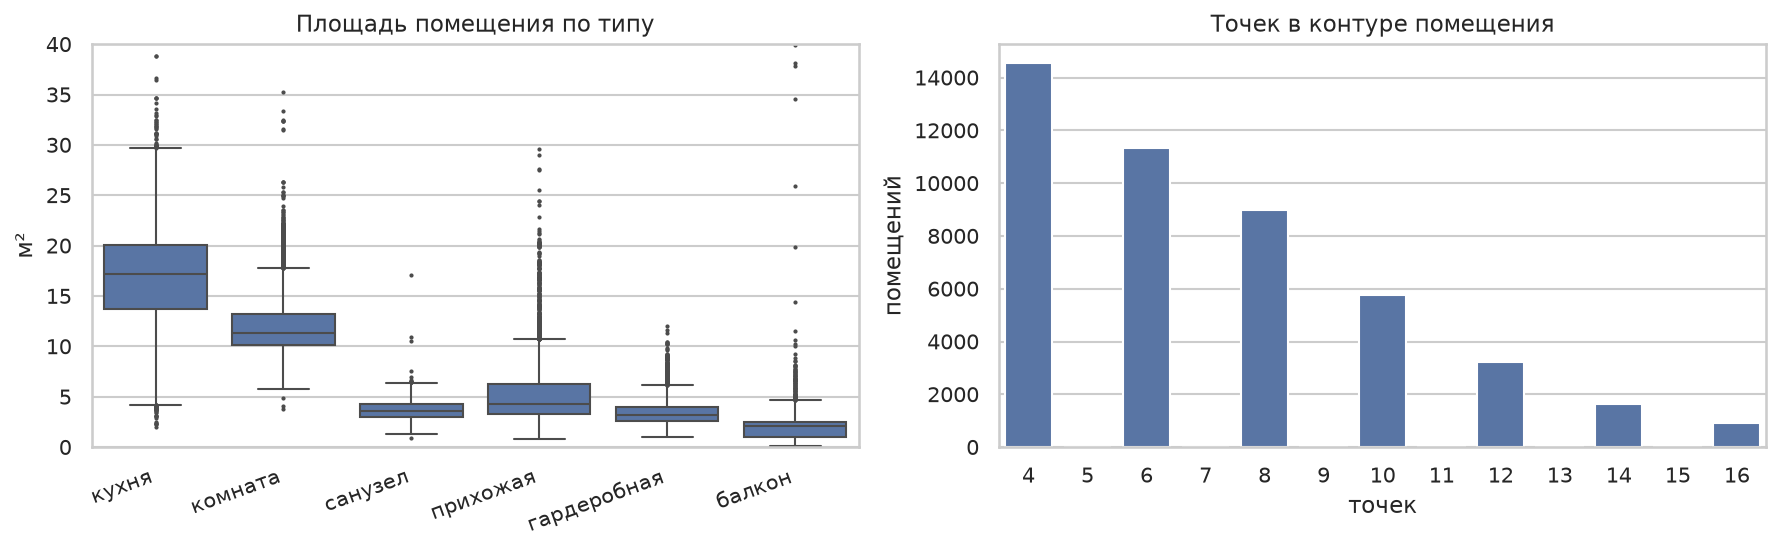

In [9]:
def is_orthogonal(polygon, tol=0.5):
    pts = np.array(polygon + polygon[:1])
    dx, dy = np.abs(np.diff(pts, axis=0)).T
    return bool(np.all((dx < tol) | (dy < tol)))


rooms["vertices"] = rooms.polygon.str.len()
rooms["orthogonal"] = rooms.polygon.map(is_orthogonal)
print(
    f"квартир с косой стеной: {flats.slanted.sum()} ({flats.slanted.mean():.1%}); помещений с косой стеной: "
    f"{(~rooms.orthogonal).sum()} ({(~rooms.orthogonal).mean():.1%})"
)
print(
    f"прямоугольных помещений (4 вершины): {(rooms.vertices == 4).mean():.1%}; "
    f"стены только горизонтальные и вертикальные: {rooms.orthogonal.mean():.1%}; "
    f"12 и больше вершин: {(rooms.vertices >= 12).mean():.1%}"
)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
main = rooms[rooms.kind.isin(KIND_COLOR)].assign(тип=lambda d: d.kind.map(KIND_NAME))
sns.boxplot(data=main, x="тип", y="area_m2", fliersize=1, ax=axes[0])
axes[0].set(title="Площадь помещения по типу", xlabel="", ylabel="м²", ylim=(0, 40))
plt.setp(axes[0].get_xticklabels(), rotation=20, ha="right")
sns.countplot(data=rooms[rooms.vertices <= 16], x="vertices", ax=axes[1])
axes[1].set(title="Точек в контуре помещения", xlabel="точек", ylabel="помещений")
plt.tight_layout()
plt.show()

Шесть типов дают 99% помещений, остальные семь - меньше 1%. Косая стена есть у 491 квартиры (6,5%) и у 2,5% помещений. Прямоугольных
помещений только 30%, у 16% контур из 12 и больше точек. Площади разных типов перекрываются: по одной площади тип не
определить.

## 5. Двери и окна

In [10]:
kind_of = dict(zip(zip(rooms.code, rooms.id, strict=True), rooms.kind, strict=True))
doors["from_kind"] = [kind_of.get((c, r), "?") for c, r in zip(doors.code, doors.room_from, strict=True)]
doors["to_kind"] = [kind_of.get((c, r), "?") for c, r in zip(doors.code, doors.room_to, strict=True)]
doors["width_m"] = doors.width_px * doors.m_per_px
show("дверей по классу:", doors["class"].value_counts())
show("ширина двери, м (доля дверей):", doors.width_m.round(1).value_counts(normalize=True).head(4).round(2))
print(f"двери 0,8-1,0 м: {doors.width_m.round(1).between(0.8, 1.0).mean():.0%}")
print(
    f"петля есть у {doors.hinge.notna().mean():.1%} дверей; "
    f"открывается в room_to у {(doors.swing_into == doors.room_to).mean():.1%}"
)
print("\nмежду какими помещениями двери (строка - откуда, столбец - куда):")
print(
    pd.crosstab(
        doors.from_kind.map(KIND_NAME).fillna("прочее"), doors.to_kind.map(KIND_NAME).fillna("вход/прочее")
    ).rename_axis(index="откуда", columns="куда")
)
windows["len_m"] = windows.segment.map(seg_len) * windows.m_per_px
windows["room_kind"] = [kind_of.get((c, r), "?") for c, r in zip(windows.code, windows.room, strict=True)]
show("\nокон по типу помещения:", windows.room_kind.map(KIND_NAME).value_counts())
low, high = windows.len_m.quantile([0.05, 0.95])
print(f"длина окна, м: медиана {windows.len_m.median():.2f}, 5-95%: {low:.2f}-{high:.2f}")
flats["n_entrance"] = flats.code.map(doors[doors["class"] == "entrance"].groupby("code").size()).fillna(0)
print(f"квартир без входной двери: {(flats.n_entrance == 0).sum()}, без окон: {(flats.n_windows == 0).sum()}")

дверей по классу:
  door: 26214
  entrance: 7542
  balcony: 108
ширина двери, м (доля дверей):
  0.8: 0.37
  0.9: 0.36
  1.0: 0.22
  1.1: 0.02
двери 0,8-1,0 м: 95%
петля есть у 100.0% дверей; открывается в room_to у 96.6%

между какими помещениями двери (строка - откуда, столбец - куда):
куда         балкон  вход/прочее  гардеробная  комната  кухня  постирочная  прихожая  санузел  терраса
откуда                                                                                                
балкон            0            0            0       37      7            0         1        2        0
гардеробная       0            7            0       98     25            5       260      110        0
комната           4           52           86      194    193            2       524       36        0
кухня             1           19          190     2872      0           13       295       37        2
постирочная       0            0            5       13      5            0        30        0

95% дверей шириной 0,8, 0,9 или 1,0 м. Сторона петли указана у всех дверей. Чаще всего двери соединяют прихожую с
санузлом, комнатой и входом, кухню с комнатой. Окна почти все в комнатах и кухнях (99%).

## 6. Повторы планировок
ПИК строит дома из типовых секций, поэтому одна и та же планировка встречается в наборе много раз под разными кодами.
Одной планировкой считаем чертежи, у которых одинаковое число помещений, а их площади отличаются не больше чем на
0,2 м². Балкон не учитываем: у той же квартиры на другом этаже его может не быть. Группы собираются по цепочке: если А
похож на Б, а Б на В, все три в одной группе. Побайтно одинаковые картинки - тоже одна планировка.

сколько получается разных планировок при разном допуске:


  0.1 м²: 5581 планировок, самая большая группа 17 чертежей


  0.2 м²: 4628 планировок, самая большая группа 53 чертежей


  0.3 м²: 3717 планировок, самая большая группа 635 чертежей


чертежей с суффиксом -vN: 27.9%; разных планировок 4628 из 7589 (61%); чертежей, у которых есть такая же планировка: 56.1%; самая частая планировка: 53 чертежей


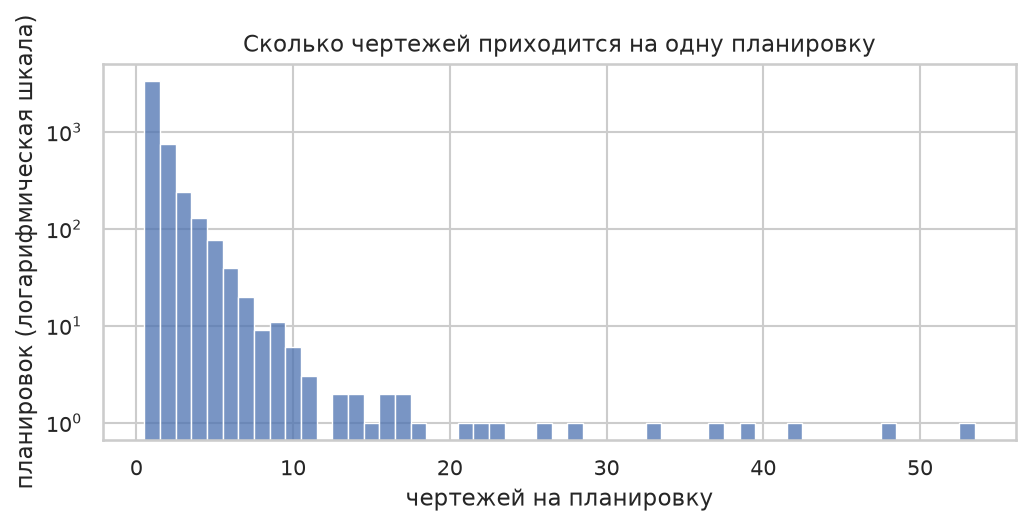

In [11]:
TOL = 0.2  # м²


def group_layouts(tol):  # номер планировки для каждого чертежа
    pairs = []
    for idx in flats.groupby(
        "n_inner"
    ).indices.values():  # одинаковое число помещений, площади отличаются не больше tol
        v = np.array([vectors[i] for i in idx])
        near = np.abs(v[:, None] - v[None]).max(axis=2) <= tol
        pairs += [(idx[i], idx[j]) for i, j in zip(*np.nonzero(near), strict=True)]
    for idx in flats.groupby("png_md5").indices.values():  # побайтно одинаковые картинки
        pairs += [(idx[0], j) for j in idx]
    rows_i, cols_j = zip(*pairs, strict=True)
    graph = coo_matrix((np.ones(len(pairs)), (rows_i, cols_j)), shape=(len(flats), len(flats)))
    return connected_components(graph, directed=False)[1]  # группы собираются по цепочке


# площади помещений по возрастанию; балкон не берём: у той же планировки на другом этаже его может не быть
vectors = [np.array(sorted(r["area_m2"] for r in d["rooms"] if r["kind"] not in ("b", "l"))) for d in labels]
flats["n_inner"] = [len(v) for v in vectors]
flats["png_md5"] = [hashlib.md5((DATASET / "images" / f"{c}.png").read_bytes()).hexdigest() for c in flats.code]
print("сколько получается разных планировок при разном допуске:")
for tol in (0.1, 0.2, 0.3):
    sizes_tol = pd.Series(group_layouts(tol)).value_counts()
    print(f"  {tol} м²: {len(sizes_tol)} планировок, самая большая группа {sizes_tol.iloc[0]} чертежей")
flats["geom_class"] = group_layouts(TOL)
flats["is_copy"] = flats.code.str.contains(r"-v\d+$")
class_size = flats.geom_class.value_counts()
print(
    f"чертежей с суффиксом -vN: {flats.is_copy.mean():.1%}; разных планировок {len(class_size)} из {len(flats)} "
    f"({len(class_size) / len(flats):.0%}); чертежей, у которых есть такая же планировка: "
    f"{(flats.geom_class.map(class_size) > 1).mean():.1%}; "
    f"самая частая планировка: {class_size.iloc[0]} чертежей"
)
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(class_size, discrete=True, ax=ax)
ax.set(
    title="Сколько чертежей приходится на одну планировку",
    xlabel="чертежей на планировку",
    ylabel="планировок (логарифмическая шкала)",
    yscale="log",
)
plt.tight_layout()
plt.show()

Разных планировок 4 628 из 7 589 (61%); у 56% чертежей в наборе есть такая же планировка, в самой большой группе 53
чертежа. Чёткой границы между «та же» и «похожая» нет: при допуске 0,1 м² групп 5 581, при 0,3 м² - 3 717, и самая
большая вырастает до 635 чертежей. Берём 0,2 м². Если делить набор случайно по чертежам, одна планировка попадёт и в
обучение, и в тест (проверка в разделе 9).

## 7. Качество разметки

Разметка построена автоматически из чертежа ПИК, руками её не проверяли. Независимая проверка одна: числа площадей с
сайта, они есть у 23% квартир. У остальных число взято из того же чертежа, что и контур, и их совпадение говорит только
о согласованности разметки. Ниже: расхождение контура с числом, сумма помещений против общей площади, пересечения
контуров, пропуски дверей и окон.

доля помещений, где площадь контура и число на картинке расходятся больше чем на 0,5 м²:
число      с сайта  с чертежа
                             
не балкон    0.008      0.013
балкон       0.610      0.012
балкон: число на картинке / площадь контура, медиана:
  с сайта: 0.32
  с чертежа: 1.0
квартир, где хоть одно помещение (без балкона) расходится с числом больше чем на 5%: 10.1%; больше чем на 5% или 0,3 м², что больше: 5.9%
сумма площадей помещений расходится с суммой чисел больше чем на 2% у 0.6% квартир


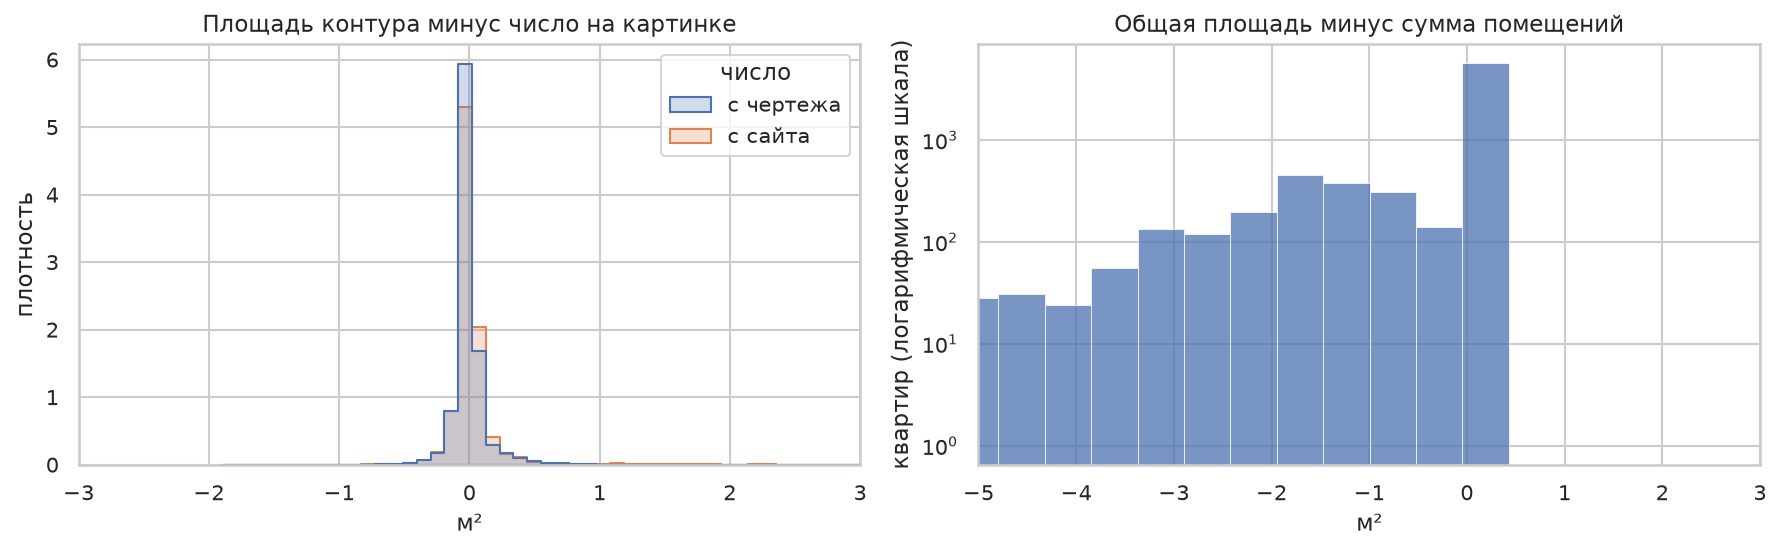

сумма помещений больше общей площади на 0,5 м²+: 1834 квартир, из них с балконом 1831


In [12]:
rooms["diff_m2"] = rooms.area_m2 - rooms.number  # площадь полигона минус число на картинке
flats["uncovered_m2"] = flats.total_m2 - flats.area_rooms
rooms["is_balcony"] = rooms.kind.isin(["b", "l"])
rooms["число"] = rooms.numbers_source.map(SOURCE_NAME)
far = (
    rooms.dropna(subset="number")
    .groupby(["is_balcony", "число"])
    .diff_m2.apply(lambda s: (s.abs() > 0.5).mean())
    .unstack()
)
print("доля помещений, где площадь контура и число на картинке расходятся больше чем на 0,5 м²:")
print(far.rename(index={False: "не балкон", True: "балкон"}).rename_axis(index="").round(3))
balcony = rooms[(rooms.kind == "b") & rooms.number.notna()]
show(
    "балкон: число на картинке / площадь контура, медиана:",
    (balcony.number / balcony.area_m2).groupby(balcony["число"]).median().round(2),
)
inner = rooms[~rooms.is_balcony & rooms.number.notna()]
off_5 = inner.diff_m2.abs() > 0.05 * inner.number
off_soft = inner.diff_m2.abs() > np.maximum(0.05 * inner.number, 0.3)
sums = inner.groupby("code")[["area_m2", "number"]].sum()
print(
    f"квартир, где хоть одно помещение (без балкона) расходится с числом больше чем на 5%: "
    f"{inner[off_5].code.nunique() / len(flats):.1%}; больше чем на 5% или 0,3 м², что больше: "
    f"{inner[off_soft].code.nunique() / len(flats):.1%}"
)
print(
    f"сумма площадей помещений расходится с суммой чисел больше чем на 2% у "
    f"{((sums.area_m2 / sums.number - 1).abs() > 0.02).mean():.1%} квартир"
)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(
    data=rooms, x="diff_m2", hue="число", bins=80, element="step", stat="density", common_norm=False, ax=axes[0]
)
axes[0].set(title="Площадь контура минус число на картинке", xlabel="м²", ylabel="плотность", xlim=(-3, 3))
sns.histplot(flats.uncovered_m2, bins=80, ax=axes[1])
axes[1].set(
    title="Общая площадь минус сумма помещений",
    xlabel="м²",
    ylabel="квартир (логарифмическая шкала)",
    xlim=(-5, 3),
    yscale="log",
)
plt.tight_layout()
plt.show()
has_balcony = flats.code.isin(rooms[rooms.is_balcony].code)
print(
    f"сумма помещений больше общей площади на 0,5 м²+: {(flats.uncovered_m2 < -0.5).sum()} квартир, "
    f"из них с балконом {((flats.uncovered_m2 < -0.5) & has_balcony).sum()}"
)

In [13]:
def overlap_m2(d):
    polys = [Polygon(r["polygon"]).buffer(0) for r in d["rooms"]]
    return sum(p.intersection(q).area for p, q in combinations(polys, 2)) * d["m_per_px"] ** 2


flats["overlap_m2"] = [overlap_m2(d) for d in labels]
lit = set(zip(windows.code, windows.room, strict=True))
rooms["has_window"] = [(c, i) in lit for c, i in zip(rooms.code, rooms.id, strict=True)]


def has_flag(frame):  # квартиры, где есть хоть одна такая строка
    return flats.code.isin(frame.code)


flags = pd.DataFrame(
    {
        "контуры помещений пересекаются": flats.overlap_m2 > 0.1,
        "нет входной двери": flats.n_entrance == 0,
        "нет окон": flats.n_windows == 0,
        "проём без двери размечен как дверь (уже 0,6 м)": has_flag(doors[doors.width_m < 0.6]),
        "дверь шире 1,6 м": has_flag(doors[doors.width_m > 1.6]),
        "есть балкон, нет балконной двери": has_balcony & ~has_flag(doors[doors["class"] == "balcony"]),
        "комната или кухня-гостиная без окна": has_flag(
            rooms[((rooms.kind == "r") | (rooms.name == "Кухня-гостиная")) & ~rooms.has_window]
        ),
        "помещение без числа площади": has_flag(rooms[rooms.number.isna()]),
        "число на картинке расходится с контуром > 0,5 м² (без балкона)": has_flag(
            rooms[~rooms.is_balcony & (rooms.diff_m2.abs() > 0.5)]
        ),
        "сумма помещений без балкона меньше общей площади на 2 м²+": (
            flats.total_m2 - flats.code.map(inner.groupby("code").area_m2.sum())
        )
        > 2,
    }
).set_index(flats.code)
print(flags.sum().rename("квартир").to_string())
doors["pair"] = (
    doors.from_kind.map(KIND_NAME).fillna("прочее") + " - " + doors.to_kind.map(KIND_NAME).fillna("вход/прочее")
)
narrow, wide = doors[doors.width_m < 0.6], doors[doors.width_m > 1.6]
show(f"\nдверей уже 0,6 м: {len(narrow)}, между какими помещениями:", narrow.pair.value_counts().head(3))
show(f"дверей шире 1,6 м: {len(wide)}, между какими помещениями:", wide.pair.value_counts().head(3))

контуры помещений пересекаются                                       0
нет входной двери                                                   47
нет окон                                                             4
проём без двери размечен как дверь (уже 0,6 м)                     477
дверь шире 1,6 м                                                    50
есть балкон, нет балконной двери                                  1927
комната или кухня-гостиная без окна                                440
помещение без числа площади                                          8
число на картинке расходится с контуром > 0,5 м² (без балкона)     468
сумма помещений без балкона меньше общей площади на 2 м²+          115

дверей уже 0,6 м: 479, между какими помещениями:
  прихожая - кухня: 435
  санузел - кухня: 12
  кухня - прихожая: 11
дверей шире 1,6 м: 59, между какими помещениями:
  комната - санузел: 12
  комната - вход/прочее: 10
  кухня - санузел: 10


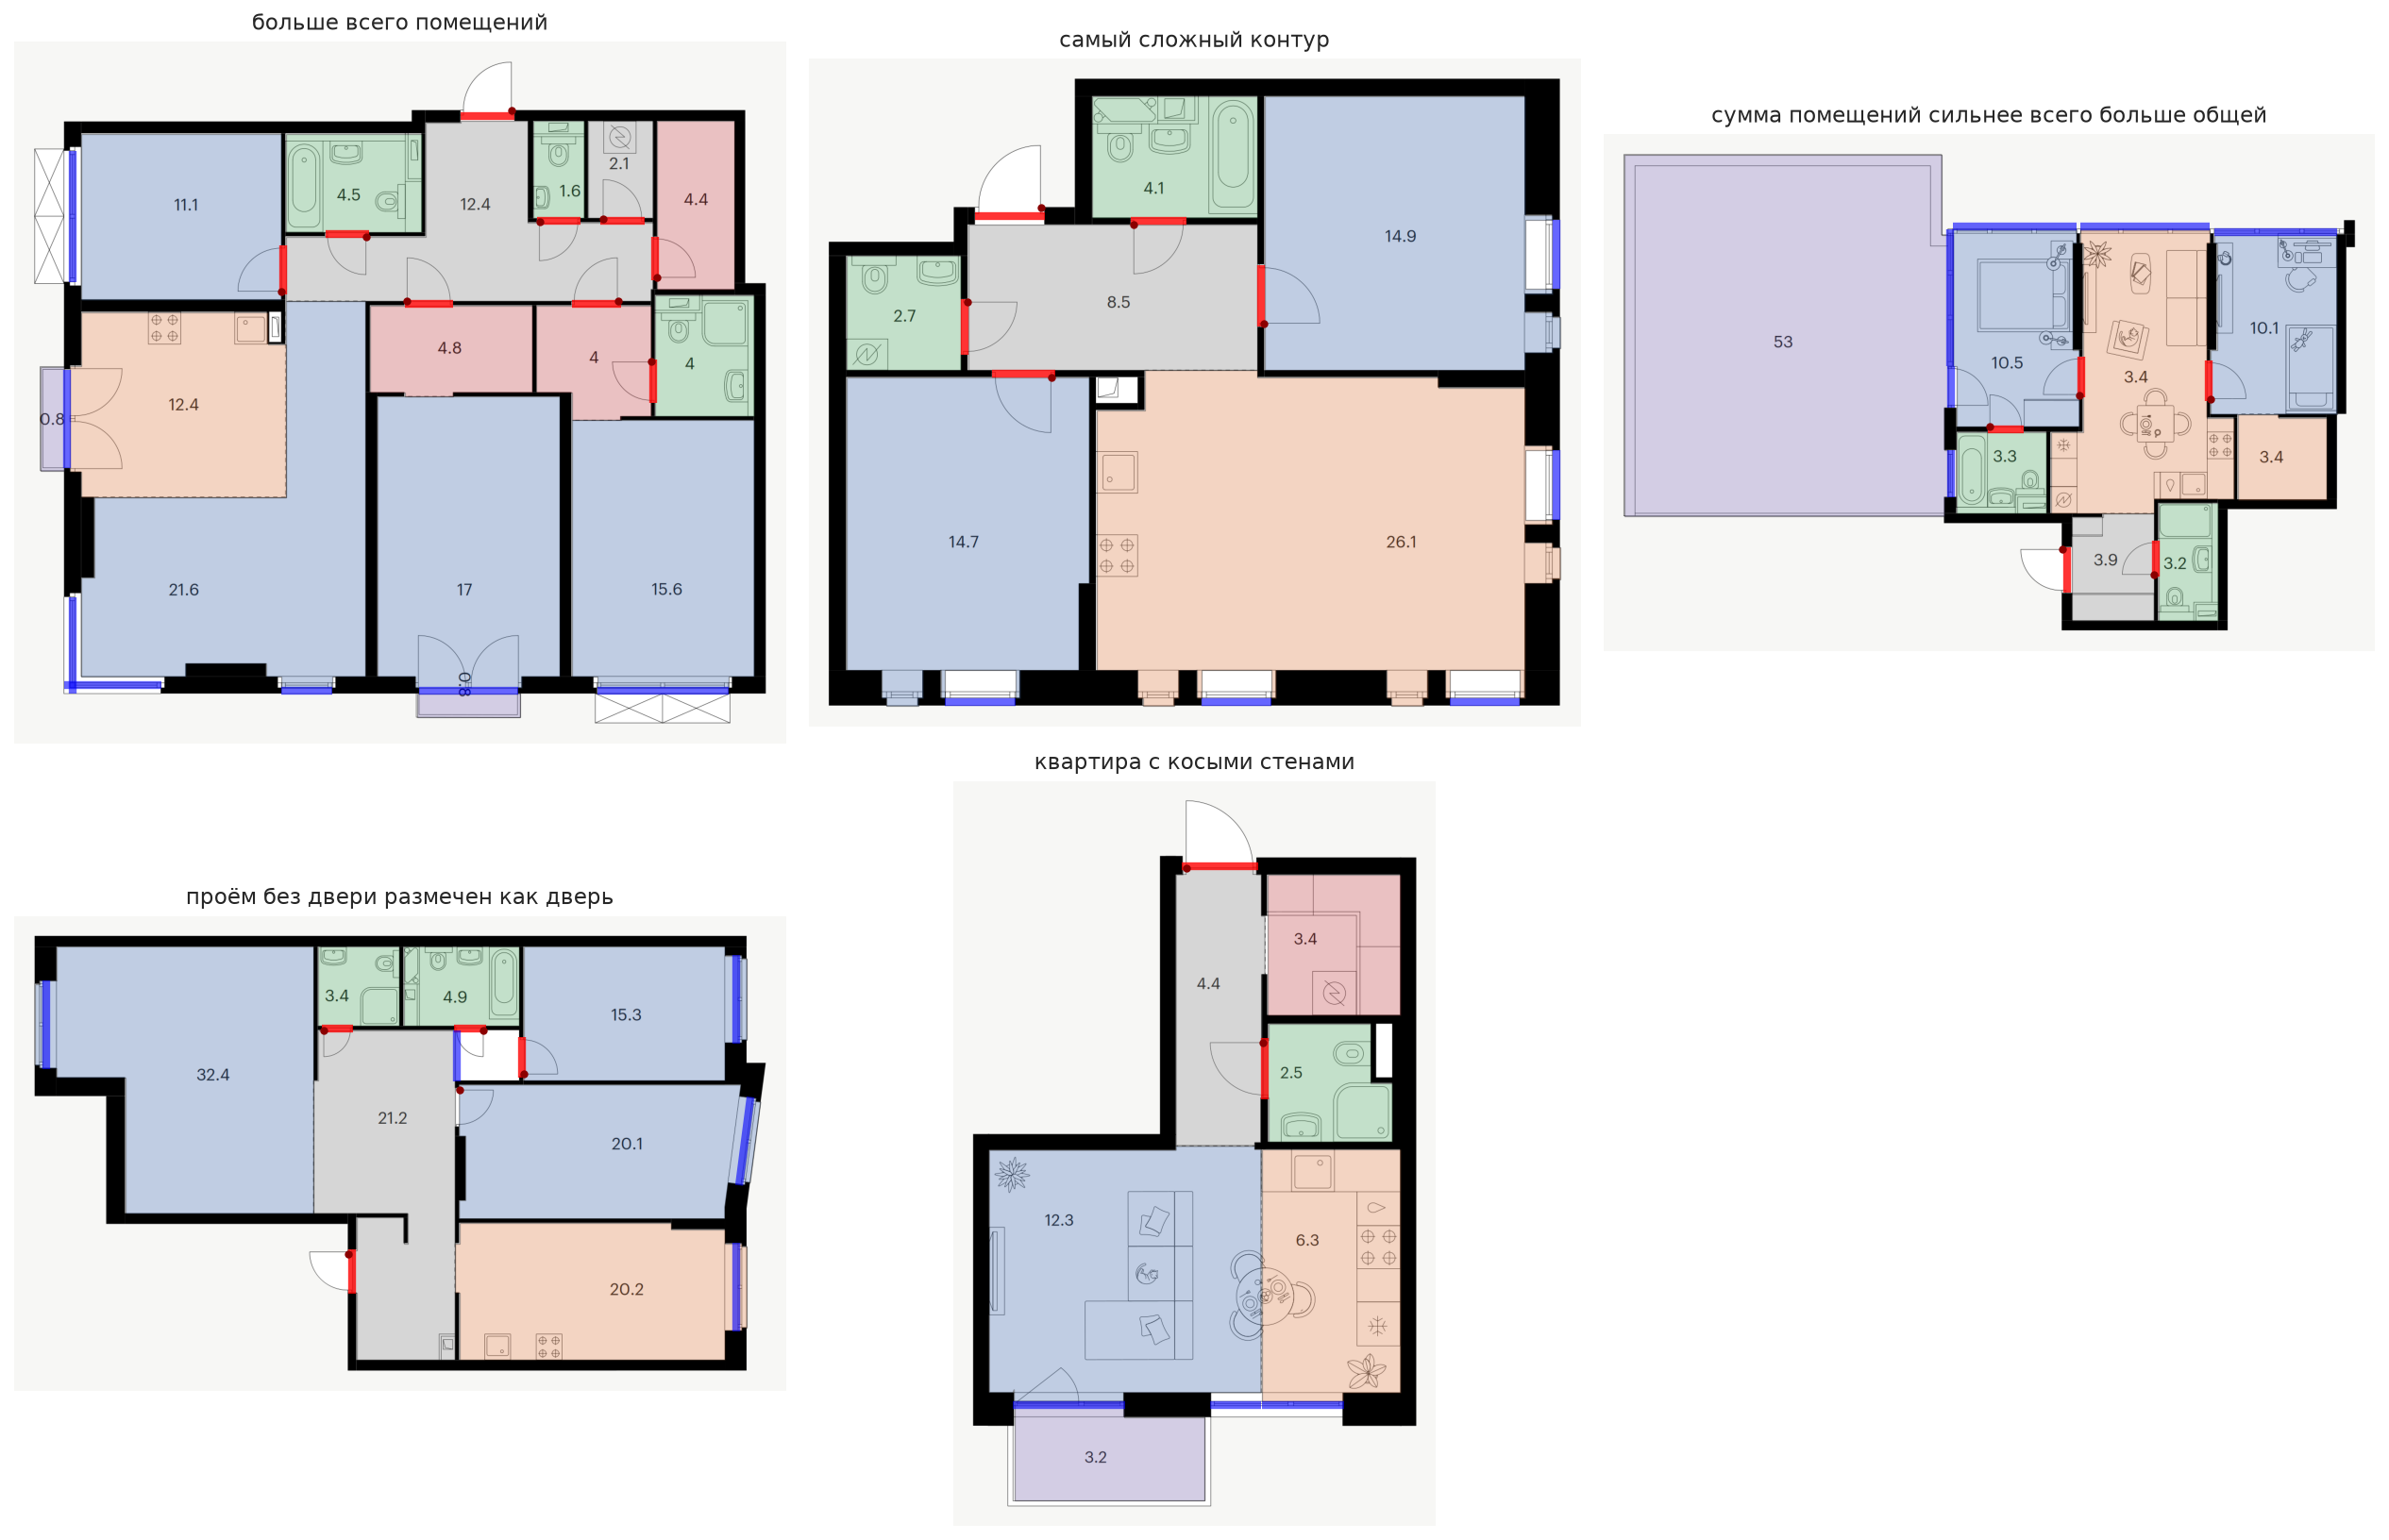

In [14]:
extremes = {
    "больше всего помещений": flats.loc[flats.n_rooms.idxmax(), "code"],
    "самый сложный контур": rooms.loc[rooms.vertices.idxmax(), "code"],
    "сумма помещений сильнее всего больше общей": flats.loc[flats.uncovered_m2.idxmin(), "code"],
    "проём без двери размечен как дверь": doors.loc[doors.width_m.idxmin(), "code"],
    "квартира с косыми стенами": flats[flats.slanted].sort_values("n_rooms").code.iloc[len(flats[flats.slanted]) // 2],
}
fig, axes = plt.subplots(2, 3, figsize=(17, 11))
axes.flat[5].set_axis_off()
for ax, (why, code) in zip(axes.flat, extremes.items(), strict=False):
    show_drawing(ax, code, title=why)
plt.tight_layout()
plt.show()

- Независимая проверка: без балконов контур расходится с числом сайта больше чем на 0,5 м² у 0,8% помещений. Там, где
число с чертежа, - у 1,3%.
- У балконов число с сайта в медиане втрое меньше площади контура: сайт печатает балкон с коэффициентом, разметка
обводит его целиком. Поэтому у 1 834 квартир сумма помещений больше общей площади, 1 831 из них с балконом.
- Правило «каждое помещение в пределах 5% от своего числа» не проходит сама разметка у 10,1% квартир; с допуском «5%
или 0,3 м², что больше» - у 5,9%. Сумма площадей расходится с суммой чисел больше чем на 2% только у 0,6% квартир.
Причину расхождений по отдельным помещениям мы не выясняли.
- У 115 квартир сумма помещений без балкона меньше общей площади на 2 м² и больше: возможно, помещение пропущено.
- Контуры помещений не пересекаются.
- Проём без двери размечен как узкая «дверь» в 477 квартирах; 435 таких дверей из 479 - между прихожей и кухней
(чертёж «проём без двери размечен как дверь»).
- Балконные двери почти не размечены: у 1 927 квартир есть балкон, но нет двери на него.
- В 440 квартирах (6%) у комнаты или кухни-гостиной нет окна в разметке. По разметке нельзя отличить пропущенное окно
от комнаты без окна.
- У 47 квартир нет входной двери, у 4 нет окон.

## 8. Фильтр для обучения

Убираем квартиры, где разметка неполная или противоречит числам: нет входной двери; нет окна у комнаты или
кухни-гостиной; дверь шире 1,6 м; помещение без числа; число на картинке расходится с контуром больше чем на 0,5 м²
(без балкона); сумма помещений заметно меньше общей площади.

Оставляем квартиры с дефектами, общими для всего набора: проём без двери, неразмеченные балконные двери, площадь
балкона. Их фильтром не убрать, они учитываются в постановке задачи (диздок, раздел 2.3).

In [15]:
DROP = [
    "контуры помещений пересекаются",
    "нет входной двери",
    "нет окон",
    "дверь шире 1,6 м",
    "комната или кухня-гостиная без окна",
    "помещение без числа площади",
    "число на картинке расходится с контуром > 0,5 м² (без балкона)",
    "сумма помещений без балкона меньше общей площади на 2 м²+",
]
flats["has_defect"] = flags[DROP].any(axis=1).to_numpy()
print(
    f"убираем из обучения {flats.has_defect.sum()} квартир ({flats.has_defect.mean():.1%}), "
    f"остаётся {(~flats.has_defect).sum()}"
)
show("доля убранных по числу жилых комнат:", flats.groupby("living_bin").has_defect.mean().reindex(LIVING).round(2))
slanted_left = (flats.slanted & ~flats.has_defect).sum()
print(f"из квартир с косой стеной убрано {flats[flats.slanted].has_defect.mean():.1%}, остаётся {slanted_left}")
gone = flats.groupby("geom_class").has_defect.all()
print(f"планировок, убранных целиком: {gone.sum()} из {len(gone)}")
clean = flats[~flats.has_defect].copy()
DATA = Path("..") / "data"
DATA.mkdir(exist_ok=True)
_ = (DATA / "clean_codes.txt").write_text("\n".join(clean.code) + "\n")

убираем из обучения 1045 квартир (13.8%), остаётся 6544
доля убранных по числу жилых комнат:
  студия: 0.05
  1: 0.11
  2: 0.15
  3+: 0.21
из квартир с косой стеной убрано 7.7%, остаётся 453
планировок, убранных целиком: 695 из 4628


Фильтр убирает 1 045 квартир (14%), остаётся 6 544. Большие квартиры убираются чаще: 21% квартир с тремя и больше
комнатами против 5% студий, потому что чем больше помещений, тем вероятнее ошибка хотя бы в одном. 695 планировок из
4 628 убраны целиком. Из 491 квартиры с косой стеной остаётся 453. Список оставшихся - в `data/clean_codes.txt`.

## 9. Деление на обучение, валидацию и тест

Делим набор после фильтра. Все чертежи одной планировки идут в одну часть, доли студий, одно-, двух- и трёхкомнатных в
частях одинаковые (`StratifiedGroupKFold`). Набор режется на 8 равных кусков: шесть - обучение, один - валидация, один -
тест. Модель обучается один раз, это не кросс-валидация. Деление записывается в `data/split.csv`.

In [16]:
folds = StratifiedGroupKFold(n_splits=8, shuffle=True, random_state=7).split(
    clean, clean.living_bin, groups=clean.geom_class
)
clean["fold"] = 0
for k, (_, idx) in enumerate(folds):
    clean.iloc[idx, clean.columns.get_loc("fold")] = k
clean["part"] = clean.fold.map({0: "test", 1: "val"}).fillna("train")
assert (clean.groupby("geom_class").part.nunique() == 1).all()
clean[["code", "part"]].to_csv(DATA / "split.csv", index=False)

balance = (
    clean.groupby("part")
    .agg(
        чертежей=("code", "size"),
        планировок=("geom_class", "nunique"),
        студий=("living_bin", lambda s: (s == "студия").mean()),
        трёх_и_больше=("living_bin", lambda s: (s == "3+").mean()),
        медиана_м2=("total_m2", "median"),
        чисел_с_сайта=("numbers_source", lambda s: (s == "site").mean()),
        помещений=("n_rooms", "mean"),
        с_косой_стеной=("slanted", "mean"),
    )
    .loc[["train", "val", "test"]]
    .rename(index={"train": "обучение", "val": "валидация", "test": "тест"})
    .round(2)
)
print(balance)


def share_with_twin(test_idx, train_idx, tol):  # доля чертежей, у которых в обучении есть такая же планировка
    train = {
        n: np.array([vectors[i] for i in train_idx if len(vectors[i]) == n])
        for n in {len(vectors[i]) for i in train_idx}
    }
    hits = [
        len(vectors[i]) in train and (np.abs(train[len(vectors[i])] - vectors[i]).max(axis=1) <= tol).any()
        for i in test_idx
    ]
    return np.mean(hits)


train_idx, test_idx = clean.index[clean.part == "train"], clean.index[clean.part == "test"]
shuffled = clean.sample(frac=1, random_state=7).index
n_test = len(test_idx)
random_share = share_with_twin(shuffled[:n_test], shuffled[2 * n_test :], TOL)
print(
    f"\nчертежей теста, у которых в обучении есть такая же планировка (допуск {TOL} м²): "
    f"наше деление {share_with_twin(test_idx, train_idx, TOL):.0%}, "
    f"случайное деление по чертежам {random_share:.0%}"
)
print(f"похожая планировка (допуск 0,5 м²) при нашем делении: {share_with_twin(test_idx, train_idx, 0.5):.0%}")

           чертежей  планировок  студий  трёх_и_больше  медиана_м2  чисел_с_сайта  помещений  с_косой_стеной
part                                                                                                        
обучение       4908        2948     0.1           0.17        49.3           0.24       6.28            0.07
валидация       818         492     0.1           0.17        49.9           0.26       6.23            0.04
тест            818         493     0.1           0.17        49.3           0.26       6.15            0.08

чертежей теста, у которых в обучении есть такая же планировка (допуск 0.2 м²): наше деление 0%, случайное деление по чертежам 47%
похожая планировка (допуск 0,5 м²) при нашем делении: 53%


In [17]:
slices = pd.Series(
    {
        "3+ жилых комнат": (flats.living_bin == "3+").mean(),
        "8 и больше помещений": (flats.n_rooms >= 8).mean(),
        "есть редкий тип помещения": flats.code.isin(rooms[~rooms.kind.isin(KIND_COLOR)].code).mean(),
        "есть балконная дверь": flats.code.isin(doors[doors["class"] == "balcony"].code).mean(),
        "помещение с 12+ вершинами": flats.code.isin(rooms[rooms.vertices >= 12].code).mean(),
        "числа с сайта": (flats.numbers_source == "site").mean(),
        "есть косая стена": flats.slanted.mean(),
    },
    name="доля квартир",
).round(3)
print(slices.to_string())

3+ жилых комнат              0.185
8 и больше помещений         0.264
есть редкий тип помещения    0.055
есть балконная дверь         0.006
помещение с 12+ вершинами    0.567
числа с сайта                0.234
есть косая стена             0.065


Обучение 4 908, валидация 818, тест 818 чертежей; разных планировок в них 2 948, 492 и 493. Части совпадают по числу
комнат, площади, числу помещений и доле чисел с сайта.

Утечки нет: ни у одного чертежа теста нет такой же планировки в обучении. При случайном делении по чертежам она была бы
у 47%. При этом у 53% чертежей теста в обучении есть похожая планировка (площади отличаются до 0,5 м²): тест проверяет
новые варианты типовых квартир ПИК, а не непохожие на них дома.

Группы квартир, по которым качество стоит считать отдельно (доли от всех 7 589): три и больше комнат (18%), 8 и больше
помещений (26%), редкие типы помещений (5,5%), контур из 12 и больше точек (57%), косая стена (6,5%, в тесте 8%). Балконная дверь есть в 0,6% квартир: для
обучения этого мало.

## 10. Чего в данных нет и выводы

Чего нет:

- картинок от клиентов: только картинки, нарисованные из чертежей ПИК, без сжатия и обрезки;
- половины планировок ПИК с косыми стенами: из 1 071 такого чертежа в набор вошёл 491. Остальные отброшены, чаще всего
из-за остеклённых эркеров и углов (359), расхождения масштаба больше 5% (181) и помещений без контура (145);
- планов других застройщиков;
- ручной проверки разметки: глазами просмотрены только примеры в разделах 1 и 7.

Выводы:

1. Объём: 7 589 чертежей, 48 тыс. помещений, 34 тыс. дверей, 25 тыс. окон; у 6,5% квартир есть косая стена. Шесть типов помещений дают 99%.
2. Объекты мелкие: стена 15 px, дверь и узкое помещение от 64 px при картинке 1984 px. Масштаб меняется в 2,5 раза.
3. Планировки повторяются: разных 61%. Делить можно только по планировкам, иначе у половины теста будет копия в
обучении.
4. Разметка автоматическая. По числам с сайта контуры верны у 99% помещений без балкона. 14% квартир убраны из-за
пропусков и противоречий, осталось 6 544.
5. Три дефекта есть во всём наборе: балкон размечен целиком, балконные двери не размечены, проём размечен как дверь.

## 11. Сценарии оценки агента

Агент получает просьбу фразой и меняет расстановку мебели в сцене. Сценарий - JSON: квартира (`template`), категория,
сложность, шаги с просьбой и ожиданием: допустимые статусы ответа, машинные проверки по сцене (`claims`), лимиты.
Наборы: основной (на нём настраивают агента), отложенный (на нём только проверяют) и сквозные прогоны.

In [18]:
SET_NAME = {"bench": "основной", "holdout": "отложенный", "scenarios": "сквозные прогоны"}
rows = []
for subset in ("bench", "holdout", "scenarios"):
    for path in sorted((AGENT / subset).glob("*.json")):
        s = load_json(path)
        for step in s.get("steps", []):
            expect = step.get("expect") or {}
            status = expect.get("status", [])
            rows.append(
                {
                    "set": SET_NAME[subset],
                    "scenario": s["name"],
                    "category": s.get("category", "без категории"),
                    "template": s.get("template"),
                    "prompt": step["prompt"],
                    "n_status": len([status] if isinstance(status, str) else status),
                    "n_claims": len(expect.get("claims") or []),
                }
            )
steps = pd.DataFrame(rows)
scenarios = steps.drop_duplicates(["set", "scenario"])
in_bench = set(scenarios[scenarios.set == "основной"].template)
table = (
    steps.groupby("set")
    .agg(
        сценариев=("scenario", "nunique"),
        шагов=("prompt", "size"),
        квартир=("template", "nunique"),
        квартир_из_основного=("template", lambda s: s[s.isin(in_bench)].nunique()),
        шагов_без_проверки=("n_claims", lambda s: (s == 0).sum()),
        с_одной=("n_claims", lambda s: (s == 1).sum()),
        с_двумя_и_больше=("n_claims", lambda s: (s >= 2).sum()),
    )
    .loc[list(SET_NAME.values())]
    .rename_axis("набор")
)
print(table.T)
top = scenarios[scenarios.set == "основной"].template.value_counts()
print(
    f"\nосновной набор: на самой частой квартире {top.iloc[0]} сценариев из {top.sum()} ({top.iloc[0] / top.sum():.0%})"
)
print(f"шагов с несколькими допустимыми исходами: {(steps.n_status > 1).mean():.0%}")
print("одинаковых просьб в разных наборах:", int((steps.groupby("prompt").set.nunique() > 1).sum()))
print("примеры просьб:", *steps.sample(3, random_state=1).prompt, sep="\n - ")

набор                 основной  отложенный  сквозные прогоны
сценариев                  154          60                13
шагов                      186          60                22
квартир                     50          24                 2
квартир_из_основного        50           0                 2
шагов_без_проверки          48          11                 9
с_одной                     83           1                11
с_двумя_и_больше            55          48                 2

основной набор: на самой частой квартире 25 сценариев из 154 (16%)
шагов с несколькими допустимыми исходами: 32%
одинаковых просьб в разных наборах: 0
примеры просьб:
 - А сколько мне будет стоить ремонт в этой квартире? Посчитай смету
 - Сделай из комнаты 9,8 мой кабинет: письменный стол с креслом, стеллаж для книг и шкаф для документов
 - Холодильник стоит у телевизора, это странно. Переставь его на кухню, к кухонному ряду


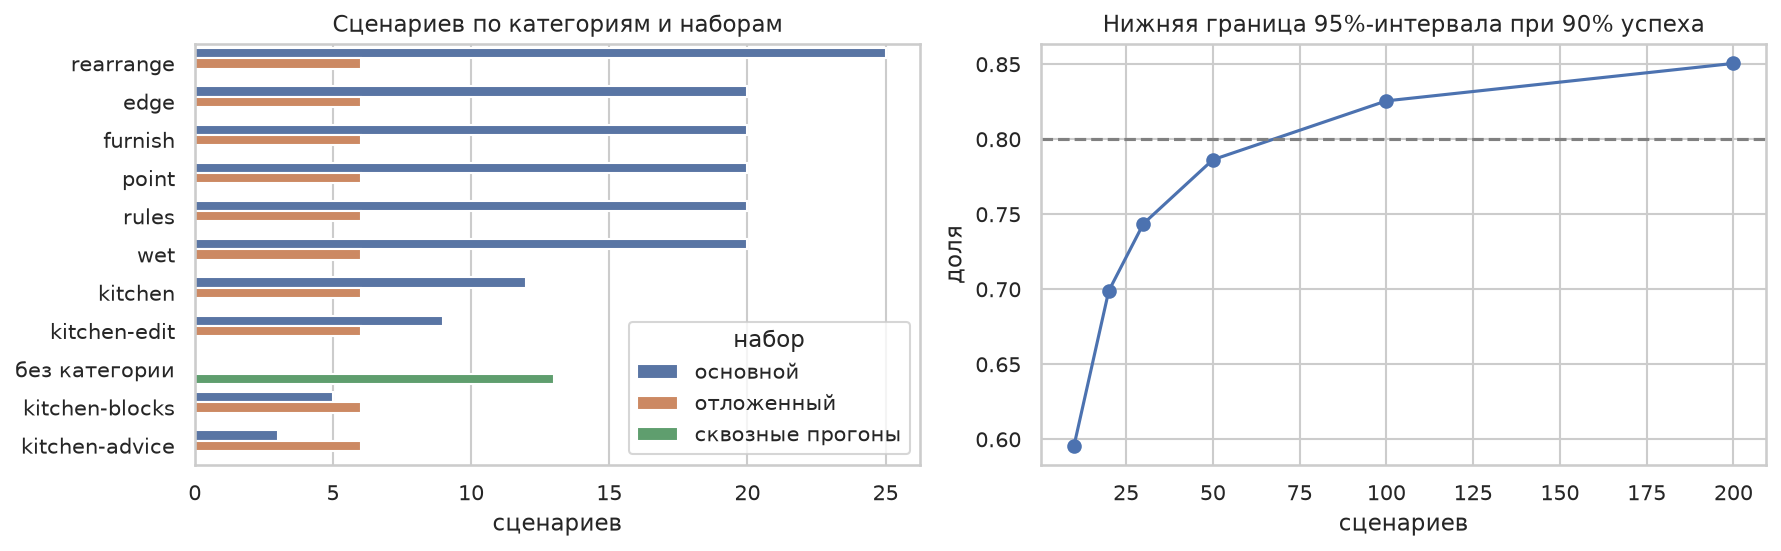

In [19]:
def wilson_lower(p, n, z=1.96):
    centre, half = p + z * z / (2 * n), z * sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return (centre - half) / (1 + z * z / n)


fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.countplot(data=scenarios, y="category", hue="set", order=scenarios.category.value_counts().index, ax=axes[0])
axes[0].set(title="Сценариев по категориям и наборам", xlabel="сценариев", ylabel="")
axes[0].get_legend().set_title("набор")
sizes_n = [10, 20, 30, 50, 100, 200]
axes[1].plot(sizes_n, [wilson_lower(0.9, n) for n in sizes_n], marker="o")
axes[1].axhline(0.8, color="gray", linestyle="--")
axes[1].set(title="Нижняя граница 95%-интервала при 90% успеха", xlabel="сценариев", ylabel="доля")
plt.tight_layout()
plt.show()

В основном наборе 154 сценария на 50 квартирах, 16% из них на одной квартире. В отложенном 60 сценариев на 24 квартирах,
ни одной из них нет в основном наборе; 10 категорий по 6 сценариев. На категорию этого мало: при 90% успеха нижняя граница
95%-интервала поднимается до 0,8 только при 50-100 сценариях (правый график). Поэтому вывод можно делать по отложенному
набору целиком, но не по категории.

Машинные проверки: в отложенном наборе у 48 шагов из 60 их две и больше, у 11 нет (верный ответ там - вопрос или отказ).
В основном наборе у 48 шагов из 186 проверки нет, у 83 она одна.